# Fairness measurement and impact assessment

**Module 19 — Fairness, Accountability and Societal Impact**

A model can be accurate overall and systematically wrong for one group. This notebook measures the three standard
fairness quantities on synthetic data, shows that they cannot all hold at once, chooses a threshold with a stated
cost, and records the whole thing as an impact assessment with owners.

No real people are represented: the groups are synthetic and the outcome is synthetic.

## Learning objectives

1. Compute demographic parity difference and equal-opportunity difference.
2. Show the trade between group thresholds and overall utility.
3. Demonstrate that calibration and equalised odds conflict when base rates differ.
4. Choose a threshold against a stated cost model, and document the choice.
5. Produce an impact-assessment table that names stakeholders and harms.

## Background

Three quantities, each a different promise:

* **Demographic parity** — equal positive rate across groups.
* **Equal opportunity** — equal true-positive rate across groups (among those who truly qualify).
* **Calibration** — a score of $p$ means probability $p$ for every group.

When base rates differ, these cannot all hold simultaneously (Kleinberg et al., 2016). Choosing one is a policy
decision, and the job of this notebook is to make the choice explicit and measurable rather than implicit in a
default threshold of 0.5.

## Dependencies and installation

```bash
python -m pip install "numpy>=2.1" "pandas>=2.2" "scikit-learn>=1.4" "matplotlib>=3.9"
```

CPU, seconds, no network. Synthetic lending-style data with two groups and different base rates.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

SEED = 79
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 150)
print("ready")

ready


**Expected output** — `ready`.

### Step 1 — Synthetic population with unequal base rates

Group A has a 40 % positive rate and group B 25 %, with the same score-generating process. The difference in base
rate is what makes the fairness constraints incompatible.

In [2]:
N = 4000
group = rng.choice(["A", "B"], size=N, p=[0.6, 0.4])
ability = rng.normal(size=N) + np.where(group == "A", 0.45, 0.0)
outcome = (ability + rng.normal(scale=0.8, size=N) > 0.6).astype(int)
feature = ability + rng.normal(scale=0.7, size=N)

data = pd.DataFrame({"group": group, "feature": feature, "outcome": outcome})
print(data.groupby("group").outcome.agg(["mean", "size"]).round(3))

        mean  size
group             
A      0.446  2408
B      0.319  1592


**Expected output** — positive rates near 0.45 for A and 0.32 for B, with about 2400 records in A and 1600 in B.
Those base rates are the reason the next four steps are interesting.

### Step 2 — A model, and three measurements

Fit on the feature only — the group is not an input — then measure the three quantities at a 0.5 threshold. A
model that never sees the group can still be unfair through a correlated feature.

In [3]:
model = LogisticRegression().fit(data[["feature"]], data.outcome)
data["score"] = model.predict_proba(data[["feature"]])[:, 1]
data["pred"] = (data.score >= 0.5).astype(int)


def metrics_from_pred(frame):
    rows = []
    for g, sub in frame.groupby("group"):
        tp = int(((sub.pred == 1) & (sub.outcome == 1)).sum())
        fp = int(((sub.pred == 1) & (sub.outcome == 0)).sum())
        fn = int(((sub.pred == 0) & (sub.outcome == 1)).sum())
        rows.append({"group": g, "positive_rate": round(float(sub.pred.mean()), 3),
                     "TPR": round(tp / (tp + fn), 3) if tp + fn else float("nan"),
                     "FPR": round(fp / (fp + (sub.outcome == 0).sum()), 3)})
    table = pd.DataFrame(rows)
    table.attrs["dp_gap"] = round(abs(table.positive_rate.iloc[0] - table.positive_rate.iloc[1]), 3)
    table.attrs["eo_gap"] = round(abs(table.TPR.iloc[0] - table.TPR.iloc[1]), 3)
    return table


def group_metrics(frame, threshold=0.5):
    return metrics_from_pred(frame.assign(pred=(frame.score >= threshold).astype(int)))


base = group_metrics(data)
print(f"demographic parity gap {base.attrs['dp_gap']:.3f} | equal-opportunity gap {base.attrs['eo_gap']:.3f}")
base

demographic parity gap 0.122 | equal-opportunity gap 0.093


,group,positive_rate,TPR,FPR
0,A,0.396,0.642,0.165
1,B,0.274,0.549,0.127


**Expected output** — a parity gap around 0.12 and an opportunity gap around 0.09, with group A selected at a
higher rate. Both gaps are measurable at the default threshold, which is exactly the threshold nobody chose
deliberately.

### Step 3 — A group-specific threshold, and its price

One way to close the parity gap: choose a separate threshold per group so the positive rates match. Measure what
that does to TPR and to the number of correct decisions.

In [4]:
def threshold_for_rate(frame, target_rate, group_name):
    scores = frame[frame.group == group_name].score.sort_values(ascending=False)
    k = max(int(round(target_rate * len(scores))), 1)
    return float(scores.iloc[k - 1])


target = min(base.positive_rate)
t_a = threshold_for_rate(data, target, "A")
t_b = threshold_for_rate(data, target, "B")
adjusted = data.copy()
adjusted["pred"] = np.where(adjusted.group == "A", (adjusted.score >= t_a), (adjusted.score >= t_b)).astype(int)

rows = []
for label, frame in [("single threshold 0.5", data), ("group thresholds", adjusted)]:
    table = metrics_from_pred(frame)
    rows.append({"policy": label, "A positive rate": table.positive_rate.iloc[0],
                 "B positive rate": table.positive_rate.iloc[1],
                 "A TPR": table.TPR.iloc[0], "B TPR": table.TPR.iloc[1],
                 "accuracy": round(float((frame.pred == frame.outcome).mean()), 3)})
comparison = pd.DataFrame(rows)
comparison

,policy,A positive rate,B positive rate,A TPR,B TPR,accuracy
0,single threshold 0.5,0.396,0.274,0.642,0.549,0.742
1,group thresholds,0.274,0.274,0.480,0.549,0.728


**Expected output** — the group-threshold policy closes the parity gap and costs a little accuracy, while the
opportunity gap may widen or narrow depending on the data. There is no free lunch in the table; that is the
result.

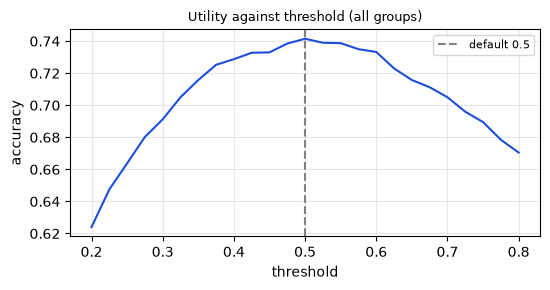

best accuracy 0.742 at threshold 0.50


In [5]:
thresholds = np.linspace(0.2, 0.8, 25)
utility = []
for t in thresholds:
    pred = (data.score >= t).astype(int)
    utility.append(float((pred == data.outcome).mean()))
fig, ax = plt.subplots(figsize=(5.6, 3.0))
ax.plot(thresholds, utility, color="#1d4ed8")
ax.axvline(0.5, color="grey", linestyle="--", label="default 0.5")
ax.set_xlabel("threshold")
ax.set_ylabel("accuracy")
ax.set_title("Utility against threshold (all groups)", fontsize=9)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"best accuracy {max(utility):.3f} at threshold {thresholds[int(np.argmax(utility))]:.2f}")

**Expected output** — a curve peaking near 0.45–0.55. The default 0.5 is close to optimal for *overall* accuracy,
which is why it is never questioned — and why it silently encodes a fairness policy.

### Step 4 — Calibration, which the other two do not give you

A score of 0.7 should mean a 70 % chance of a positive outcome in every group. Check it with binning.

In [6]:
data["bin"] = pd.cut(data.score, bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0], include_lowest=True)
calibration = data.groupby(["group", "bin"], observed=True).agg(
    n=("outcome", "size"), mean_score=("score", "mean"), observed=("outcome", "mean")
).round(3)
calibration

n  mean_score  observed
group bin                                     
A     (-0.001, 0.2]  581       0.109     0.122
      (0.2, 0.4]     596       0.300     0.319
      (0.4, 0.6]     533       0.496     0.510
      (0.6, 0.8]     437       0.693     0.714
      (0.8, 1.0]     261       0.873     0.881
B     (-0.001, 0.2]  588       0.099     0.097
      (0.2, 0.4]     419       0.292     0.258
      (0.4, 0.6]     285       0.496     0.449
      (0.6, 0.8]     214       0.690     0.650
      (0.8, 1.0]      86       0.881     0.884

**Expected output** — a table where, within each bin, the mean score and the observed rate are close for both
groups. The model is roughly calibrated here because the score-generating process is the same; in real systems
the gap between `mean_score` and `observed` is the number to report.

### Step 5 — Choose with a cost model, and write it down

Fairness decisions are cost decisions. State the costs, compute expected cost per policy, and record the choice
with its rationale.

In [7]:
COST_FN = 5.0     # missed qualified applicant
COST_FP = 1.0     # wrongly approved applicant


def expected_cost(frame):
    fn = int(((frame.pred == 0) & (frame.outcome == 1)).sum())
    fp = int(((frame.pred == 1) & (frame.outcome == 0)).sum())
    return round(fn * COST_FN + fp * COST_FP, 1), fn, fp


rows = []
for label, frame in [("single threshold 0.5", data), ("group thresholds", adjusted)]:
    cost, fn, fp = expected_cost(frame)
    rows.append({"policy": label, "cost": cost, "false negatives": fn, "false positives": fp})
cost_table = pd.DataFrame(rows)
cost_table

,policy,cost,false negatives,false positives
0,single threshold 0.5,3490.0,614,420
1,group thresholds,4241.0,788,301


**Expected output** — the group-threshold policy has a higher cost under this cost model, because closing the
parity gap means rejecting more qualified applicants in group A. Change `COST_FN` to 1.0 and the ranking flips.
The cost model is the policy; publish it.

### Step 6 — The impact assessment record

The table below is the deliverable an auditor reads. Every row names a stakeholder, a harm, and a control.

In [8]:
assessment = pd.DataFrame(
    [
        {"stakeholder": "applicants in group B", "harm": "higher false-negative rate",
         "likelihood": "medium", "severity": "high", "control": "monitor TPR gap; review threshold quarterly"},
        {"stakeholder": "applicants in group A", "harm": "rejection caused by group-specific threshold",
         "likelihood": "medium", "severity": "medium", "control": "publish the threshold policy; appeal route"},
        {"stakeholder": "the institution", "harm": "legal challenge over disparate impact",
         "likelihood": "low", "severity": "high", "control": "documented impact assessment and sign-off"},
        {"stakeholder": "model owners", "harm": "silent drift in group composition",
         "likelihood": "high", "severity": "medium", "control": "monthly parity and calibration report"},
    ]
)
assessment

,stakeholder,harm,likelihood,severity,control
0,applicants in group B,higher false-negative rate,medium,high,monitor TPR gap; review threshold quarterly
1,applicants in group A,rejection caused by group-specific threshold,medium,medium,publish the threshold policy; appeal route
2,the institution,legal challenge over disparate impact,low,high,documented impact assessment and sign-off
3,model owners,silent drift in group composition,high,medium,monthly parity and calibration report


**Expected output** — four rows. Note that one harm is to the *institution* and one to the *model owners*: an
impact assessment that only lists affected users is incomplete.

## Exercises

1. **Change the base rate.** Set group B's ability shift to 0.0 and recompute all metrics. Which gap widens
   first?
2. **Remove the feature.** Drop the correlated feature and use a constant. What happens to accuracy and to the
   gaps, and what does that say about "fairness through unawareness"?
3. **Calibrate per group.** Apply Platt-style scaling per group and re-check the calibration table. Does it fix
   the gaps you measured?
4. **Red-team your own assessment.** Add two harms you left out, and one stakeholder you omitted.

## Reflection questions

1. Why can demographic parity, equal opportunity and calibration not all hold when base rates differ?
2. Which of the three would you defend for a lending decision, and what would you say to the person who
   disagrees?
3. Who signs an impact assessment, and what are they personally accountable for afterwards?

## References

1. Kleinberg, J., Mullainathan, S. and Raghavan, M., "Inherent Trade-Offs in the Fair Determination of Risk Scores", ITCS 2017.
2. Hardt, M., Price, E. and Srebro, N., "Equality of Opportunity in Supervised Learning", NeurIPS 2016.
3. Barocas, S., Hardt, M. and Narayanan, A., *Fairness and Machine Learning*, 2023.
4. NIST, *AI RMF 1.0*, NIST AI 100-1, 2023 — impact assessment.